In [18]:
import pandas as pd
import pandas as pd
from pathlib import Path

project_dir = Path.cwd().parent  # notebook is inside the notebooks folder

customers = pd.read_csv(project_dir / "data" / "cleaned" / "customers_cleaned.csv")
policies = pd.read_csv(project_dir / "data" / "cleaned" / "policies_cleaned.csv")
vehicles = pd.read_csv(project_dir / "data" / "cleaned" / "vehicles_cleaned.csv")
claims = pd.read_csv(project_dir / "data" / "cleaned" / "claims_cleaned.csv")
payments = pd.read_csv(project_dir / "data" / "cleaned" / "payments_cleaned.csv")

print("Customers:", customers.shape)
print("Policies:", policies.shape)
print("Vehicles:", vehicles.shape)
print("Claims:", claims.shape)
print("Payments:", payments.shape)

Customers: (20000, 9)
Policies: (25000, 12)
Vehicles: (25000, 8)
Claims: (10000, 17)
Payments: (7000, 7)


In [3]:
total_policies = policies["policy_id"].nunique()
active_policies = (policies["policy_status"] == "Active").sum()
expired_policies = (policies["policy_status"] == "Expired").sum()
cancelled_policies = (policies["policy_status"] == "Cancelled").sum()
renewed_policies = (policies["policy_status"] == "Renewed").sum()

total_premium = policies["premium_amount"].sum()
average_premium = policies["premium_amount"].mean()

total_claims = claims["claim_id"].nunique()
total_claim_amount = claims["claim_amount"].sum()
average_claim_amount = claims["claim_amount"].mean()

approval_rate = (
    (claims["claim_status"] == "Approved").sum() / total_claims * 100
)
rejection_rate = (
    (claims["claim_status"] == "Rejected").sum() / total_claims * 100
)

settlement_days = claims["claim_settlement_days"].dropna()
average_settlement_days = settlement_days.mean()

kpis = {
    "Total policies": total_policies,
    "Active policies": active_policies,
    "Expired policies": expired_policies,
    "Cancelled policies": cancelled_policies,
    "Renewed policies": renewed_policies,
    "Total premium": round(total_premium, 2),
    "Average premium": round(average_premium, 2),
    "Total claims": total_claims,
    "Total claim amount": round(total_claim_amount, 2),
    "Average claim amount": round(average_claim_amount, 2),
    "Claim approval rate (%)": round(approval_rate, 2),
    "Claim rejection rate (%)": round(rejection_rate, 2),
    "Average settlement days": round(average_settlement_days, 2),
}

for name, value in kpis.items():
    print(f"{name}: {value}")

Total policies: 25000
Active policies: 7551
Expired policies: 10464
Cancelled policies: 320
Renewed policies: 6665
Total premium: 795568771.71
Average premium: 31822.75
Total claims: 10000
Total claim amount: 2885436440.65
Average claim amount: 288543.64
Claim approval rate (%): 37.9
Claim rejection rate (%): 11.6
Average settlement days: 23.93


In [4]:
# Premium by policy type
print("Premium by policy type")
display(
    policies.groupby("policy_type")
    .agg(
        policy_count=("policy_id", "nunique"),
        total_premium=("premium_amount", "sum"),
        average_premium=("premium_amount", "mean"),
    )
    .round(2)
    .sort_values("total_premium", ascending=False)
)

# Claim volume and average amount by claim type
print("Claims by claim type")
display(
    claims.groupby("claim_type")
    .agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    )
    .round(2)
    .sort_values("total_claim_amount", ascending=False)
)

# Claim volume and average amount by region
claim_regions = claims.merge(
    customers[["customer_id", "state"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

print("Claims by state")
display(
    claim_regions.groupby("state")
    .agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    )
    .round(2)
    .sort_values("total_claim_amount", ascending=False)
)

Premium by policy type


,policy_count,total_premium,average_premium
policy_type,,,
Comprehensive,15085,5.449636e+08,36126.19
Zero Depreciation,3700,1.750783e+08,47318.45
Third Party,6215,7.552694e+07,12152.36


Claims by claim type


,claim_count,total_claim_amount,average_claim_amount
claim_type,,,
Accident,4838,1.377621e+09,284750.19
Third Party Damage,2022,5.954065e+08,294464.14
Theft,1585,4.551719e+08,287174.72
Natural Disaster,796,2.300795e+08,289044.59
Fire,759,2.271571e+08,299284.75


Claims by state


,claim_count,total_claim_amount,average_claim_amount
state,,,
Telangana,1164,3.341096e+08,287035.77
Maharashtra,1178,3.267958e+08,277415.77
Tamil Nadu,884,2.687250e+08,303987.54
Gujarat,883,2.659895e+08,301233.86
Andhra Pradesh,859,2.593388e+08,301907.83
Karnataka,870,2.536982e+08,291607.16
Kerala,617,1.859532e+08,301382.84
Uttar Pradesh,608,1.725703e+08,283832.71
Rajasthan,615,1.715416e+08,278929.45


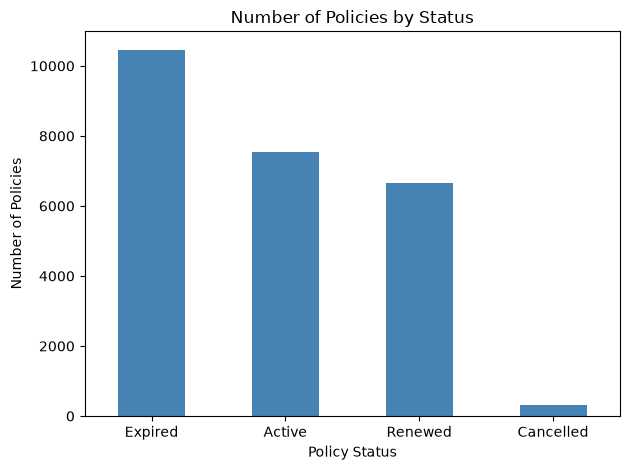

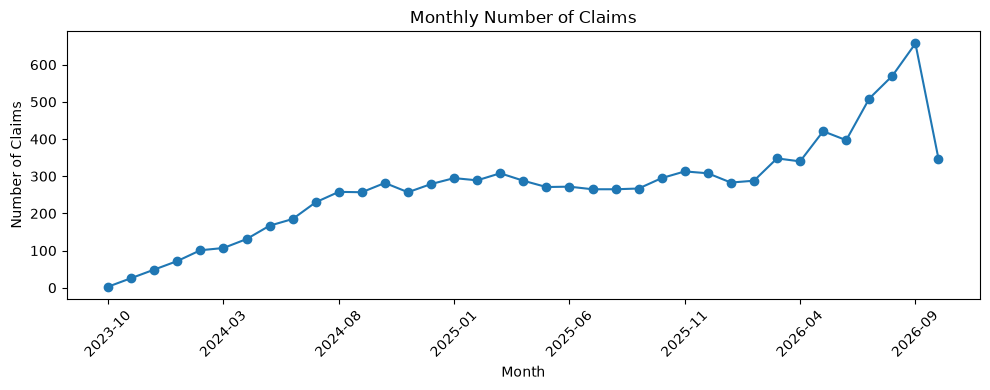

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Policies by status
policies["policy_status"].value_counts().plot(
    kind="bar",
    title="Number of Policies by Status",
    xlabel="Policy Status",
    ylabel="Number of Policies",
    color="steelblue",
    rot=0,
)
plt.tight_layout()
plt.show()

# Claims by month
claims["claim_date"] = pd.to_datetime(claims["claim_date"], errors="coerce")
monthly_claims = (
    claims.dropna(subset=["claim_date"])
    .assign(month=lambda df: df["claim_date"].dt.to_period("M").astype(str))
    .groupby("month")["claim_id"]
    .nunique()
)

monthly_claims.plot(
    kind="line",
    marker="o",
    title="Monthly Number of Claims",
    xlabel="Month",
    ylabel="Number of Claims",
    figsize=(10, 4),
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

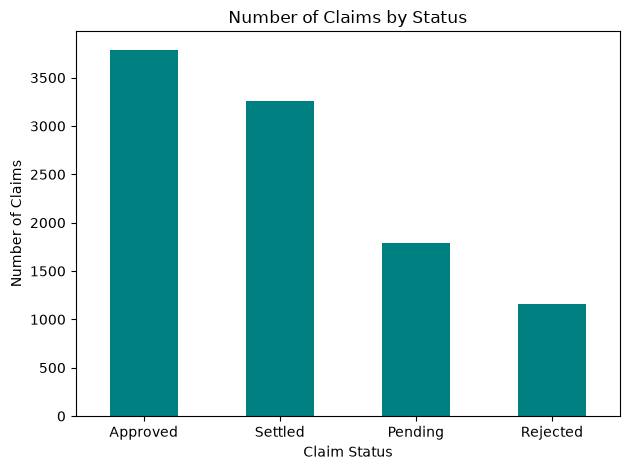

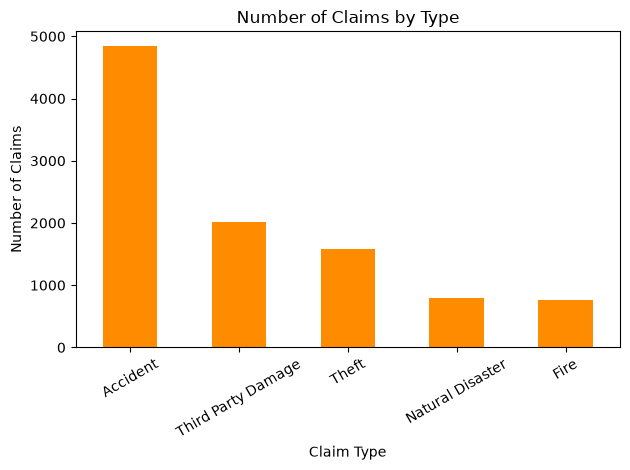

In [7]:
# Number of claims by status
claims["claim_status"].value_counts().plot(
    kind="bar",
    title="Number of Claims by Status",
    xlabel="Claim Status",
    ylabel="Number of Claims",
    color="teal",
    rot=0,
)
plt.tight_layout()
plt.show()

# Number of claims by type
claims["claim_type"].value_counts().plot(
    kind="bar",
    title="Number of Claims by Type",
    xlabel="Claim Type",
    ylabel="Number of Claims",
    color="darkorange",
    rot=30,
)
plt.tight_layout()
plt.show()

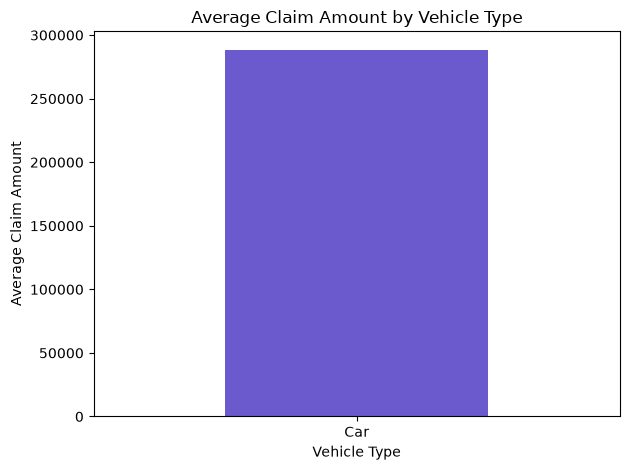

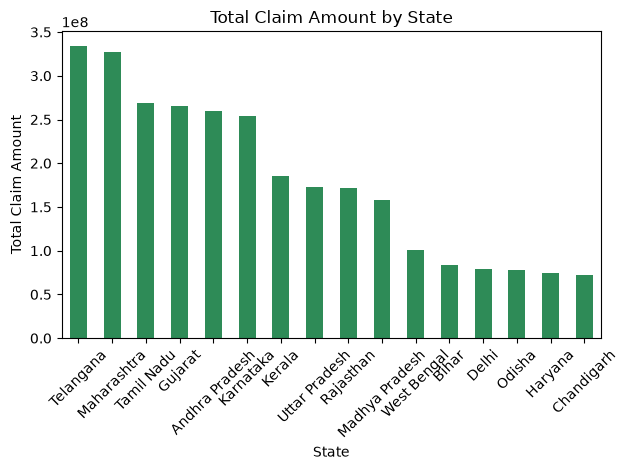

In [8]:
# Average claim amount by vehicle type
claim_vehicles = claims.merge(
    policies[["policy_id", "vehicle_id"]],
    on="policy_id",
    how="left",
    validate="many_to_one",
).merge(
    vehicles[["vehicle_id", "vehicle_type"]],
    on="vehicle_id",
    how="left",
    validate="many_to_one",
)

claim_vehicles.groupby("vehicle_type")["claim_amount"].mean().sort_values(
    ascending=False
).plot(
    kind="bar",
    title="Average Claim Amount by Vehicle Type",
    xlabel="Vehicle Type",
    ylabel="Average Claim Amount",
    color="slateblue",
    rot=0,
)
plt.tight_layout()
plt.show()

# Total claim amount by state
claim_regions.groupby("state")["claim_amount"].sum().sort_values(
    ascending=False
).plot(
    kind="bar",
    title="Total Claim Amount by State",
    xlabel="State",
    ylabel="Total Claim Amount",
    color="seagreen",
    rot=45,
)
plt.tight_layout()
plt.show()

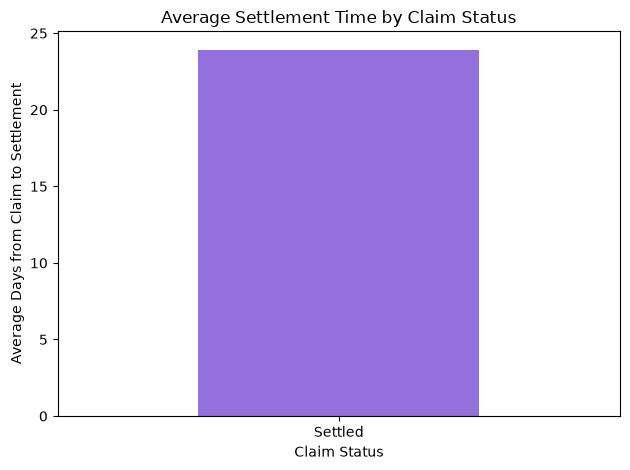

In [9]:
claims["claim_settlement_days"] = pd.to_numeric(
    claims["claim_settlement_days"], errors="coerce"
)

settlement_by_status = (
    claims.dropna(subset=["claim_settlement_days"])
    .groupby("claim_status")["claim_settlement_days"]
    .mean()
    .sort_values(ascending=False)
)

settlement_by_status.plot(
    kind="bar",
    title="Average Settlement Time by Claim Status",
    xlabel="Claim Status",
    ylabel="Average Days from Claim to Settlement",
    color="mediumpurple",
    rot=0,
)
plt.tight_layout()
plt.show()

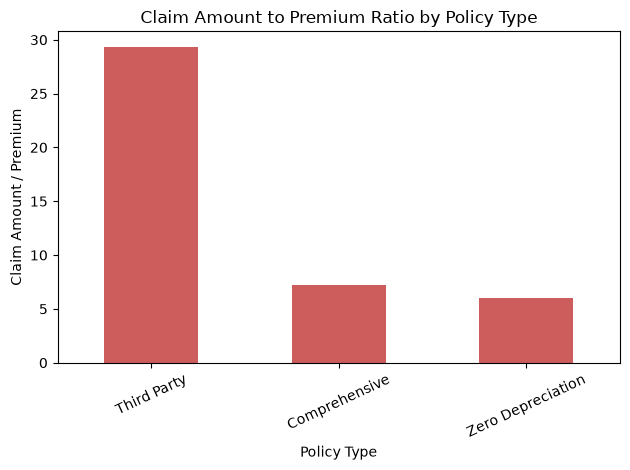

,total_claim_amount,total_premium,claim_to_premium_ratio
policy_type,,,
Comprehensive,1.572127e+09,2.164958e+08,7.262
Third Party,8.841049e+08,3.015616e+07,29.318
Zero Depreciation,4.292049e+08,7.109360e+07,6.037


In [10]:
# Total claim amounts joined to each policy type
claims_by_policy_type = claims.merge(
    policies[["policy_id", "policy_type", "premium_amount"]],
    on="policy_id",
    how="left",
    validate="many_to_one",
)

risk_by_policy_type = claims_by_policy_type.groupby("policy_type").agg(
    total_claim_amount=("claim_amount", "sum"),
    total_premium=("premium_amount", "sum"),
)

risk_by_policy_type["claim_to_premium_ratio"] = (
    risk_by_policy_type["total_claim_amount"]
    / risk_by_policy_type["total_premium"]
)

risk_by_policy_type["claim_to_premium_ratio"].sort_values(
    ascending=False
).plot(
    kind="bar",
    title="Claim Amount to Premium Ratio by Policy Type",
    xlabel="Policy Type",
    ylabel="Claim Amount / Premium",
    color="indianred",
    rot=25,
)

plt.tight_layout()
plt.show()

display(risk_by_policy_type.round(3))

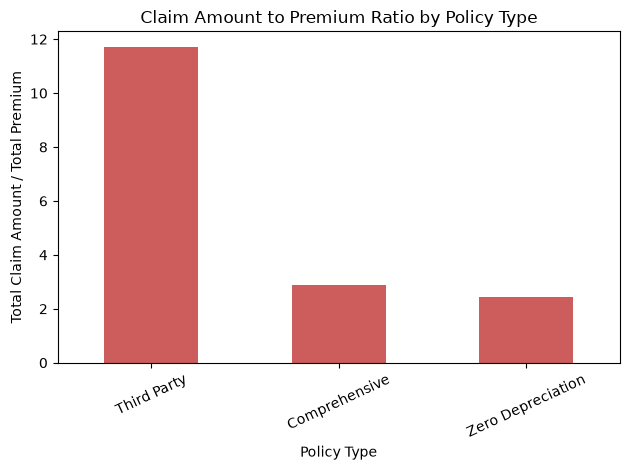

,total_claim_amount,total_premium,claim_to_premium_ratio
policy_type,,,
Comprehensive,1.572127e+09,5.449636e+08,2.885
Third Party,8.841049e+08,7.552694e+07,11.706
Zero Depreciation,4.292049e+08,1.750783e+08,2.452


In [11]:
# Claim amounts by policy type: each claim counted once
claim_totals = (
    claims.merge(
        policies[["policy_id", "policy_type"]],
        on="policy_id",
        how="left",
        validate="many_to_one",
    )
    .groupby("policy_type")["claim_amount"]
    .sum()
)

# Premium by policy type: each policy counted once
premium_totals = policies.groupby("policy_type")["premium_amount"].sum()

risk_by_policy_type = pd.DataFrame({
    "total_claim_amount": claim_totals,
    "total_premium": premium_totals,
})

risk_by_policy_type["claim_to_premium_ratio"] = (
    risk_by_policy_type["total_claim_amount"]
    / risk_by_policy_type["total_premium"]
)

risk_by_policy_type["claim_to_premium_ratio"].sort_values(
    ascending=False
).plot(
    kind="bar",
    title="Claim Amount to Premium Ratio by Policy Type",
    xlabel="Policy Type",
    ylabel="Total Claim Amount / Total Premium",
    color="indianred",
    rot=25,
)

plt.tight_layout()
plt.show()
display(risk_by_policy_type.round(3))

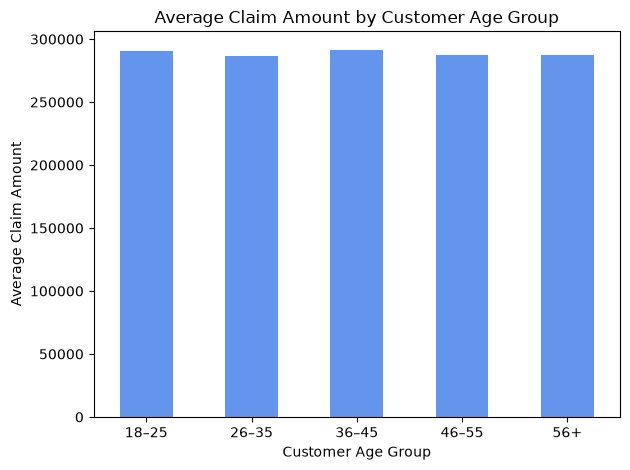

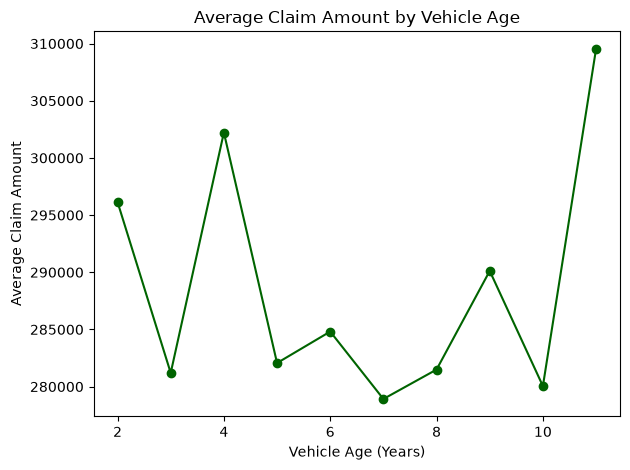

In [12]:
# Add customer age to each claim
claims_by_customer_age = claims.merge(
    customers[["customer_id", "customer_age"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

claims_by_customer_age["customer_age_group"] = pd.cut(
    claims_by_customer_age["customer_age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18–25", "26–35", "36–45", "46–55", "56+"],
)

claims_by_customer_age.groupby(
    "customer_age_group", observed=False
)["claim_amount"].mean().plot(
    kind="bar",
    title="Average Claim Amount by Customer Age Group",
    xlabel="Customer Age Group",
    ylabel="Average Claim Amount",
    color="cornflowerblue",
    rot=0,
)
plt.tight_layout()
plt.show()

# Add vehicle year to each claim, then calculate vehicle age
claims_by_vehicle_age = (
    claims.merge(
        policies[["policy_id", "vehicle_id"]],
        on="policy_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        vehicles[["vehicle_id", "vehicle_year"]],
        on="vehicle_id",
        how="left",
        validate="many_to_one",
    )
)

analysis_year = pd.Timestamp.today().year
claims_by_vehicle_age["vehicle_age"] = (
    analysis_year - claims_by_vehicle_age["vehicle_year"]
)

claims_by_vehicle_age.groupby("vehicle_age")["claim_amount"].mean().plot(
    kind="line",
    marker="o",
    title="Average Claim Amount by Vehicle Age",
    xlabel="Vehicle Age (Years)",
    ylabel="Average Claim Amount",
    color="darkgreen",
)
plt.tight_layout()
plt.show()

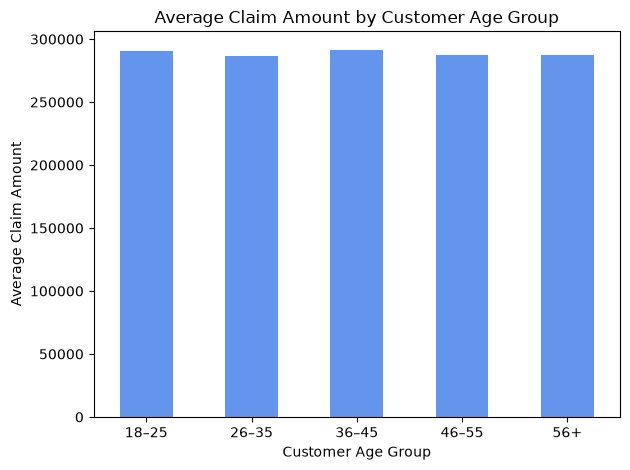

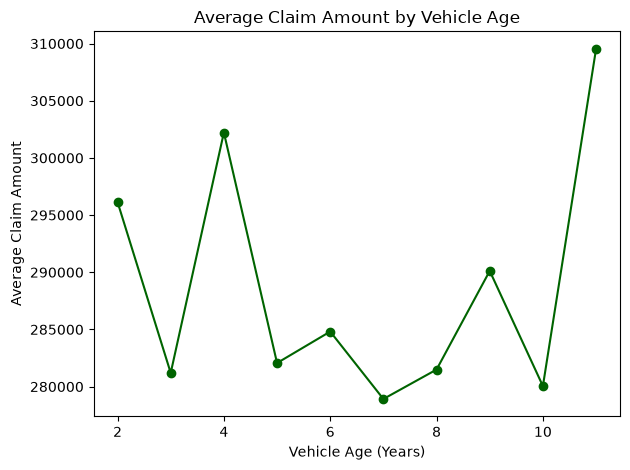

In [13]:
# Add customer age to each claim
claims_by_customer_age = claims.merge(
    customers[["customer_id", "customer_age"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

claims_by_customer_age["customer_age_group"] = pd.cut(
    claims_by_customer_age["customer_age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18–25", "26–35", "36–45", "46–55", "56+"],
)

claims_by_customer_age.groupby(
    "customer_age_group", observed=False
)["claim_amount"].mean().plot(
    kind="bar",
    title="Average Claim Amount by Customer Age Group",
    xlabel="Customer Age Group",
    ylabel="Average Claim Amount",
    color="cornflowerblue",
    rot=0,
)
plt.tight_layout()
plt.show()

# Add vehicle year to each claim, then calculate vehicle age
claims_by_vehicle_age = (
    claims.merge(
        policies[["policy_id", "vehicle_id"]],
        on="policy_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        vehicles[["vehicle_id", "vehicle_year"]],
        on="vehicle_id",
        how="left",
        validate="many_to_one",
    )
)

analysis_year = pd.Timestamp.today().year
claims_by_vehicle_age["vehicle_age"] = (
    analysis_year - claims_by_vehicle_age["vehicle_year"]
)

claims_by_vehicle_age.groupby("vehicle_age")["claim_amount"].mean().plot(
    kind="line",
    marker="o",
    title="Average Claim Amount by Vehicle Age",
    xlabel="Vehicle Age (Years)",
    ylabel="Average Claim Amount",
    color="darkgreen",
)
plt.tight_layout()
plt.show()

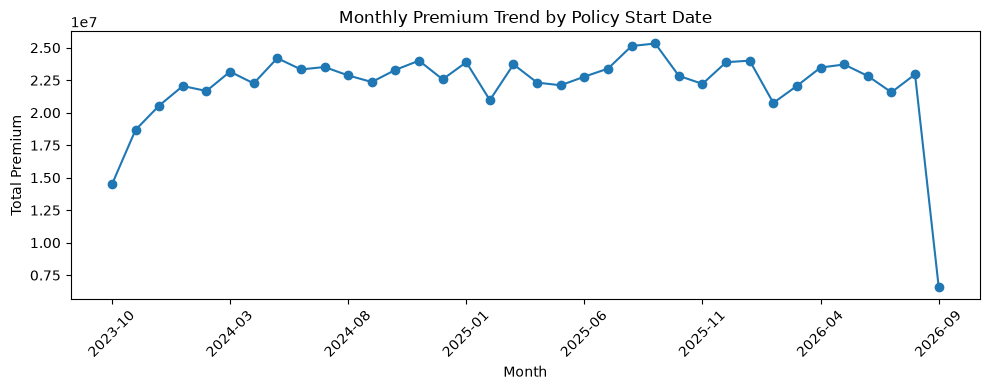

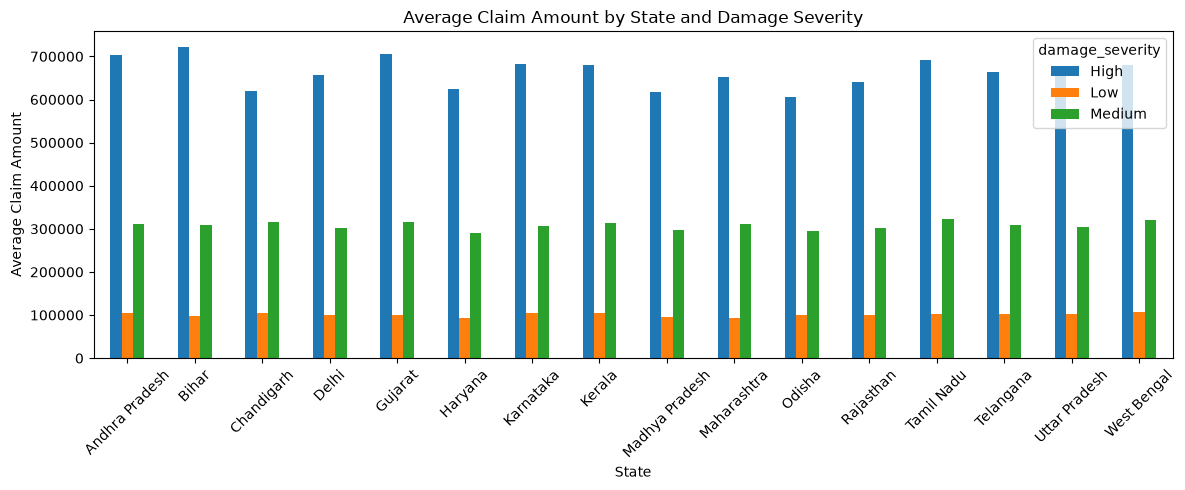

In [14]:
# Monthly premium trend, grouped by policy start month
policies["policy_start_date"] = pd.to_datetime(
    policies["policy_start_date"], errors="coerce"
)

monthly_premium = (
    policies.dropna(subset=["policy_start_date"])
    .assign(month=lambda df: df["policy_start_date"].dt.to_period("M").astype(str))
    .groupby("month")["premium_amount"]
    .sum()
)

monthly_premium.plot(
    kind="line",
    marker="o",
    title="Monthly Premium Trend by Policy Start Date",
    xlabel="Month",
    ylabel="Total Premium",
    figsize=(10, 4),
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Average claim amount by state and damage severity
claim_severity_region = claim_regions.pivot_table(
    index="state",
    columns="damage_severity",
    values="claim_amount",
    aggfunc="mean",
)

claim_severity_region.plot(
    kind="bar",
    title="Average Claim Amount by State and Damage Severity",
    xlabel="State",
    ylabel="Average Claim Amount",
    figsize=(12, 5),
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Descriptive statistics for premium, claim amount, and settlement time
settlement_days = pd.to_numeric(
    claims["claim_settlement_days"], errors="coerce"
)

statistics = pd.DataFrame({
    "premium_amount": policies["premium_amount"],
    "claim_amount": claims["claim_amount"],
    "settlement_days": settlement_days,
})

display(
    statistics.agg(["mean", "median", "std", "var"]).round(2)
)

print("Mode values:")
for column in statistics.columns:
    modes = statistics[column].mode()
    print(f"{column}: {modes.tolist()}")

,premium_amount,claim_amount,settlement_days
mean,3.182275e+04,2.885436e+05,23.93
median,2.891766e+04,2.050401e+05,24.00
std,1.809940e+04,2.630481e+05,9.85
var,3.275883e+08,6.919430e+10,96.96


Mode values:
premium_amount: [100000.0]
claim_amount: [12281.47, 13270.04, 14165.24, 14406.86, 15412.33, 17318.91, 17502.68, 17583.16, 18513.86, 19045.16, 19363.69, 19759.56, 20031.09, 20060.14, 20217.97, 20919.94, 20963.28, 21052.69, 21103.65, 21111.24, 21168.8, 21355.83, 21374.3, 21398.71, 21451.21, 21477.77, 21583.3, 21714.36, 21788.7, 21790.64, 21851.51, 21888.88, 22055.38, 22159.06, 22380.48, 22530.52, 22637.63, 22647.01, 22756.46, 22806.2, 22824.27, 22906.71, 22966.1, 23035.02, 23219.92, 23252.39, 23339.7, 23389.15, 23525.66, 23541.54, 23565.47, 23649.99, 23666.92, 23765.98, 23815.93, 23832.82, 23883.39, 24100.46, 24161.94, 24200.26, 24257.55, 24321.4, 24354.71, 24383.86, 24502.2, 24544.78, 24682.52, 24713.9, 24831.07, 24871.34, 24914.21, 25008.27, 25041.33, 25044.47, 25045.59, 25133.93, 25310.56, 25570.01, 25665.68, 25715.72, 25778.94, 25862.02, 25914.39, 25916.32, 25923.45, 26079.27, 26090.55, 26097.34, 26136.98, 26163.32, 26249.18, 26269.13, 26354.98, 26388.14, 26396.75, 26400

In [16]:
"""KPI and business analysis functions for motor insurance."""


def calculate_total_customers(data):
    """Return the number of unique customers."""
    return data["customers"]["customer_id"].nunique()


def calculate_total_policies(data):
    """Return the number of unique policies."""
    return data["policies"]["policy_id"].nunique()


def calculate_policies_by_status(data, status):
    """Count policies with the requested status."""
    policies = data["policies"]
    return int((policies["policy_status"] == status).sum())


def calculate_active_policies(data):
    """Count active policies."""
    return calculate_policies_by_status(data, "Active")


def calculate_expired_policies(data):
    """Count expired policies."""
    return calculate_policies_by_status(data, "Expired")


def calculate_cancelled_policies(data):
    """Count cancelled policies."""
    return calculate_policies_by_status(data, "Cancelled")


def calculate_renewed_policies(data):
    """Count renewed policies."""
    return calculate_policies_by_status(data, "Renewed")


def calculate_total_premium(data):
    """Return total premium across policies."""
    return float(data["policies"]["premium_amount"].sum())


def calculate_average_premium(data):
    """Return average premium per policy."""
    return float(data["policies"]["premium_amount"].mean())


def calculate_average_coverage(data):
    """Return average coverage amount per policy."""
    return float(data["policies"]["coverage_amount"].mean())


def calculate_total_claims(data):
    """Return the number of unique claims."""
    return data["claims"]["claim_id"].nunique()


def calculate_claims_by_status(data, status):
    """Count claims with the requested status."""
    return int((data["claims"]["claim_status"] == status).sum())


def calculate_approved_claims(data):
    """Count claims whose status is Approved."""
    return calculate_claims_by_status(data, "Approved")


def calculate_rejected_claims(data):
    """Count claims whose status is Rejected."""
    return calculate_claims_by_status(data, "Rejected")


def calculate_pending_claims(data):
    """Count claims whose status is Pending."""
    return calculate_claims_by_status(data, "Pending")


def calculate_total_claim_amount(data):
    """Return total requested claim amount."""
    return float(data["claims"]["claim_amount"].sum())


def calculate_average_claim_amount(data):
    """Return average requested claim amount."""
    return float(data["claims"]["claim_amount"].mean())


def calculate_claim_approval_rate(data):
    """Return approved claims as a percentage of all claims."""
    total = calculate_total_claims(data)
    return calculate_approved_claims(data) / total * 100 if total else 0.0


def calculate_claim_rejection_rate(data):
    """Return rejected claims as a percentage of all claims."""
    total = calculate_total_claims(data)
    return calculate_rejected_claims(data) / total * 100 if total else 0.0


def calculate_average_claim_settlement_days(data):
    """Return average settlement days for claims with a settlement date."""
    days = data["claims"]["claim_settlement_days"].dropna()
    return float(days.mean()) if not days.empty else 0.0


def calculate_total_payment_amount(data):
    """Return total amount recorded in payment rows."""
    return float(data["payments"]["payment_amount"].sum())


def calculate_average_payment_amount(data):
    """Return average amount per payment record."""
    return float(data["payments"]["payment_amount"].mean())


def calculate_claim_to_premium_ratio(data):
    """Return total claim amount divided by total policy premium."""
    premium = calculate_total_premium(data)
    return calculate_total_claim_amount(data) / premium if premium else 0.0


def calculate_paid_claim_ratio(data):
    """Return total payment amount divided by total claim amount."""
    claims = calculate_total_claim_amount(data)
    return calculate_total_payment_amount(data) / claims if claims else 0.0

In [17]:
def calculate_average_claim_processing_days(data):
    """Return average days from claim registration to approval."""
    days = data["claims"]["claim_processing_days"].dropna()
    return float(days.mean()) if not days.empty else 0.0


def calculate_premium_by_policy_type(data):
    """Return policy count and premium measures by policy type."""
    policies = data["policies"]
    return policies.groupby("policy_type").agg(
        policy_count=("policy_id", "nunique"),
        total_premium=("premium_amount", "sum"),
        average_premium=("premium_amount", "mean"),
    ).sort_values("total_premium", ascending=False)


def analyze_customer_claims(data):
    """Summarize claim activity by customer."""
    claims = data["claims"]
    customers = data["customers"]

    summary = claims.groupby("customer_id").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    )
    return customers.merge(summary, on="customer_id", how="left").fillna(
        {"claim_count": 0, "total_claim_amount": 0, "average_claim_amount": 0}
    )


def analyze_customer_premium(data):
    """Summarize policy and premium amounts by customer."""
    summary = data["policies"].groupby("customer_id").agg(
        policy_count=("policy_id", "nunique"),
        total_premium=("premium_amount", "sum"),
        average_premium=("premium_amount", "mean"),
    )
    return data["customers"].merge(summary, on="customer_id", how="left").fillna(
        {"policy_count": 0, "total_premium": 0, "average_premium": 0}
    )


def analyze_vehicle_claims(data):
    """Summarize claims by vehicle type, make, and model."""
    claim_vehicle = (
        data["claims"].merge(
            data["policies"][["policy_id", "vehicle_id"]],
            on="policy_id",
            how="left",
            validate="many_to_one",
        ).merge(
            data["vehicles"][["vehicle_id", "vehicle_type", "vehicle_make", "vehicle_model"]],
            on="vehicle_id",
            how="left",
            validate="many_to_one",
        )
    )
    return claim_vehicle.groupby(["vehicle_type", "vehicle_make", "vehicle_model"]).agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("total_claim_amount", ascending=False)


def analyze_vehicle_risk_patterns(data):
    """Compare vehicle characteristics with claim count and amount."""
    claim_vehicle = (
        data["claims"].merge(
            data["policies"][["policy_id", "vehicle_id"]],
            on="policy_id",
            how="left",
            validate="many_to_one",
        ).merge(
            data["vehicles"][["vehicle_id", "vehicle_type", "vehicle_make", "vehicle_year", "fuel_type"]],
            on="vehicle_id",
            how="left",
            validate="many_to_one",
        )
    )
    claim_vehicle["vehicle_age"] = pd.Timestamp.today().year - claim_vehicle["vehicle_year"]
    return claim_vehicle.groupby(
        ["vehicle_type", "vehicle_make", "fuel_type", "vehicle_age"]
    ).agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("total_claim_amount", ascending=False)


def analyze_claim_type(data):
    """Summarize claim count and amounts by claim type."""
    return data["claims"].groupby("claim_type").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("total_claim_amount", ascending=False)


def analyze_claim_status(data):
    """Summarize claim count and amounts by claim status."""
    return data["claims"].groupby("claim_status").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("claim_count", ascending=False)


def analyze_policy_type(data):
    """Summarize policy count, premium, and claims by policy type."""
    policies = data["policies"]
    claims = data["claims"].merge(
        policies[["policy_id", "policy_type"]],
        on="policy_id",
        how="left",
        validate="many_to_one",
    )
    policy_summary = policies.groupby("policy_type").agg(
        policy_count=("policy_id", "nunique"),
        total_premium=("premium_amount", "sum"),
        average_premium=("premium_amount", "mean"),
    )
    claim_summary = claims.groupby("policy_type").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
    )
    return policy_summary.join(claim_summary, how="left").fillna(0)


def analyze_region(data):
    """Summarize claim count and amounts by customer state."""
    claims_by_state = data["claims"].merge(
        data["customers"][["customer_id", "state"]],
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
    return claims_by_state.groupby("state").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("total_claim_amount", ascending=False)


def analyze_vehicle_type(data):
    """Summarize claim count and amounts by vehicle type."""
    claim_vehicle = data["claims"].merge(
        data["policies"][["policy_id", "vehicle_id"]],
        on="policy_id",
        how="left",
        validate="many_to_one",
    ).merge(
        data["vehicles"][["vehicle_id", "vehicle_type"]],
        on="vehicle_id",
        how="left",
        validate="many_to_one",
    )
    return claim_vehicle.groupby("vehicle_type").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("total_claim_amount", ascending=False)


def analyze_damage_severity(data):
    """Summarize claim count and amounts by damage severity."""
    return data["claims"].groupby("damage_severity").agg(
        claim_count=("claim_id", "nunique"),
        total_claim_amount=("claim_amount", "sum"),
        average_claim_amount=("claim_amount", "mean"),
    ).sort_values("total_claim_amount", ascending=False)

In [20]:
from pathlib import Path

project_dir = Path.cwd().parent
analysis_file = project_dir / "src" / "insurance_analysis.py"

print("Project folder:", project_dir)
print("Analysis file exists:", analysis_file.exists())
print("Analysis file path:", analysis_file)

if analysis_file.exists():
    print("Contains calculate_total_policies:",
          "def calculate_total_policies" in analysis_file.read_text(encoding="utf-8"))

Project folder: c:\Users\saite\OneDrive\Documents\motor_insurance_analytics
Analysis file exists: True
Analysis file path: c:\Users\saite\OneDrive\Documents\motor_insurance_analytics\src\insurance_analysis.py
Contains calculate_total_policies: False


In [21]:
def calculate_total_policies(data):
    """Return the number of unique policies."""
    return data["policies"]["policy_id"].nunique()


def calculate_active_policies(data):
    """Return the number of active policies."""
    return int((data["policies"]["policy_status"] == "Active").sum())


def calculate_total_premium(data):
    """Return total premium across policies."""
    return float(data["policies"]["premium_amount"].sum())


def calculate_total_claims(data):
    """Return the number of unique claims."""
    return data["claims"]["claim_id"].nunique()


def calculate_claim_approval_rate(data):
    """Return approved claims as a percentage of all claims."""
    total = calculate_total_claims(data)
    approved = int((data["claims"]["claim_status"] == "Approved").sum())
    return approved / total * 100 if total else 0.0


def calculate_average_claim_amount(data):
    """Return average claim amount."""
    return float(data["claims"]["claim_amount"].mean())

In [22]:
import sys
from pathlib import Path

project_dir = Path.cwd().parent
sys.path.insert(0, str(project_dir))

from src.data_loader import load_all_data

raw_data = load_all_data(project_dir / "data" / "raw")

for table_name, df in raw_data.items():
    print(f"{table_name}: {df.shape}")

customers: (20000, 8)
policies: (25000, 10)
vehicles: (25000, 8)
claims: (10000, 12)
payments: (7000, 7)


In [23]:
from src.validation import validate_all_tables

validate_all_tables(raw_data)
print("All tables passed validation.")

All tables passed validation.


In [25]:
from src.data_cleaner import clean_data, save_cleaned_data

cleaned_data = clean_data(raw_data)

cleaned_folder = project_dir / "data" / "cleaned"
save_cleaned_data(cleaned_data, cleaned_folder)

print("Saved cleaned files to:", cleaned_folder)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [26]:
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)
print("Loaded cleaner from:", cleaner.__file__)

Loaded cleaner from: c:\Users\saite\OneDrive\Documents\motor_insurance_analytics\src\data_cleaner.py


In [28]:
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)

cleaned_data = cleaner.clean_data(raw_data)
cleaned_folder = project_dir / "data" / "cleaned"
cleaner.save_cleaned_data(cleaned_data, cleaned_folder)

print("Saved cleaned files to:", cleaned_folder)

ValueError: Business rule check failed: 59 policies end before their start date

In [29]:
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)

cleaned_data = cleaner.clean_data(raw_data)

cleaned_folder = project_dir / "data" / "cleaned"
cleaner.save_cleaned_data(cleaned_data, cleaned_folder)

print("Saved cleaned files to:", cleaned_folder)

ValueError: Business rule check failed: 59 policies end before their start date

In [30]:
import inspect
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)
print(inspect.getsource(cleaner.validate_business_rules))

def validate_business_rules(data):
    """Check that monetary values are not negative and policy dates are valid."""
    money_columns = {
        "vehicles": ["vehicle_value"],
        "policies": ["premium_amount", "coverage_amount"],
        "claims": ["claim_amount"],
        "payments": ["payment_amount"],
    }

    errors = []

    for table_name, columns in money_columns.items():
        for column in columns:
            invalid = data[table_name][column] < 0
            if invalid.any():
                errors.append(
                    f"{table_name}.{column} has {int(invalid.sum())} negative values"
                )

    policies = data["policies"]
    invalid_dates = (
        policies["policy_start_date"].notna()
        & policies["policy_end_date"].notna()
        & (policies["policy_end_date"] < policies["policy_start_date"])
    )

    if invalid_dates.any():
        errors.append(
            f"{int(invalid_dates.sum())} policies end before their start date"
      

In [31]:
import importlib
import src.validation as validation

importlib.reload(validation)

validation.validate_all_tables(raw_data)
print("Validation finished.")

Validation finished.


c:\Users\saite\OneDrive\Documents\motor_insurance_analytics\src\validation.py:242: UserWarning: 59 policies have an end date before their start date. The cleaning step will flag these records.
  warnings.warn(


In [40]:
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)

<module 'src.data_cleaner' from 'c:\\Users\\saite\\OneDrive\\Documents\\motor_insurance_analytics\\src\\data_cleaner.py'>

In [44]:
cleaned_data = cleaner.clean_data(raw_data)

cleaned_folder = project_dir / "data" / "cleaned"
cleaner.save_cleaned_data(cleaned_data, cleaned_folder)

print("Saved cleaned files to:", cleaned_folder)

ValueError: Business rule check failed: 59 policies end before their start date

In [38]:
import inspect
import src.data_cleaner as cleaner

print(inspect.getsource(cleaner.validate_business_rules))

def validate_business_rules(data):
    """Check that monetary values are not negative and policy dates are valid."""
    money_columns = {
        "vehicles": ["vehicle_value"],
        "policies": ["premium_amount", "coverage_amount"],
        "claims": ["claim_amount"],
        "payments": ["payment_amount"],
    }

    errors = []

    for table_name, columns in money_columns.items():
        for column in columns:
            invalid = data[table_name][column] < 0
            if invalid.any():
                errors.append(
                    f"{table_name}.{column} has {int(invalid.sum())} negative values"
                )

    policies = data["policies"]
    invalid_dates = (
        policies["policy_start_date"].notna()
        & policies["policy_end_date"].notna()
        & (policies["policy_end_date"] < policies["policy_start_date"])
    )

    if invalid_dates.any():
        errors.append(
            f"{int(invalid_dates.sum())} policies end before their start date"
      

In [43]:
inspect.getsource(cleaner.validate_business_rules)

'def validate_business_rules(data):\n    """Check that monetary values are not negative and policy dates are valid."""\n    money_columns = {\n        "vehicles": ["vehicle_value"],\n        "policies": ["premium_amount", "coverage_amount"],\n        "claims": ["claim_amount"],\n        "payments": ["payment_amount"],\n    }\n\n    errors = []\n\n    for table_name, columns in money_columns.items():\n        for column in columns:\n            invalid = data[table_name][column] < 0\n            if invalid.any():\n                errors.append(\n                    f"{table_name}.{column} has {int(invalid.sum())} negative values"\n                )\n\n    policies = data["policies"]\n    invalid_dates = (\n        policies["policy_start_date"].notna()\n        & policies["policy_end_date"].notna()\n        & (policies["policy_end_date"] < policies["policy_start_date"])\n    )\n\n    policies["policy_date_issue"] = invalid_dates\n    \n    if invalid_dates.any():\n        print(f"Warning

In [45]:
raw_data = load_all_data(project_dir / "data" / "raw")

for name, df in raw_data.items():
    print(f"{name}: {df.shape}")

customers: (20000, 8)
policies: (25000, 10)
vehicles: (25000, 8)
claims: (10000, 12)
payments: (7000, 7)


In [46]:
import importlib
import src.validation as validation

importlib.reload(validation)
validation.validate_all_tables(raw_data)

print("Validation finished.")

Validation finished.


c:\Users\saite\OneDrive\Documents\motor_insurance_analytics\src\validation.py:233: UserWarning: 59 policies have an end date before their start date. The cleaning step will flag these records.
  


In [47]:
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)

cleaned_data = cleaner.clean_data(raw_data)

cleaned_folder = project_dir / "data" / "cleaned"
cleaner.save_cleaned_data(cleaned_data, cleaned_folder)

print("Cleaning finished. Files saved to:", cleaned_folder)

NameError: name 'invalid_dates' is not defined

In [48]:
import importlib
import src.data_cleaner as cleaner

importlib.reload(cleaner)

cleaned_data = cleaner.clean_data(raw_data)

cleaned_folder = project_dir / "data" / "cleaned"
cleaner.save_cleaned_data(cleaned_data, cleaned_folder)

print("Cleaning finished. Files saved to:", cleaned_folder)

Cleaning finished. Files saved to: c:\Users\saite\OneDrive\Documents\motor_insurance_analytics\data\cleaned


In [49]:
import importlib
import src.insurance_analysis as analysis

importlib.reload(analysis)

<module 'src.insurance_analysis' from 'c:\\Users\\saite\\OneDrive\\Documents\\motor_insurance_analytics\\src\\insurance_analysis.py'>

In [50]:
import importlib
import src.insurance_analysis as analysis

importlib.reload(analysis)

data = {
    "customers": customers,
    "policies": policies,
    "vehicles": vehicles,
    "claims": claims,
    "payments": payments,
}

print("Total policies:", analysis.calculate_total_policies(data))
print("Active policies:", analysis.calculate_active_policies(data))
print("Total premium:", round(analysis.calculate_total_premium(data), 2))
print("Total claims:", analysis.calculate_total_claims(data))
print("Claim approval rate (%):",
      round(analysis.calculate_claim_approval_rate(data), 2))
print("Average claim amount:",
      round(analysis.calculate_average_claim_amount(data), 2))

Total policies: 25000
Active policies: 7551
Total premium: 795568771.71
Total claims: 10000
Claim approval rate (%): 37.9
Average claim amount: 288543.64


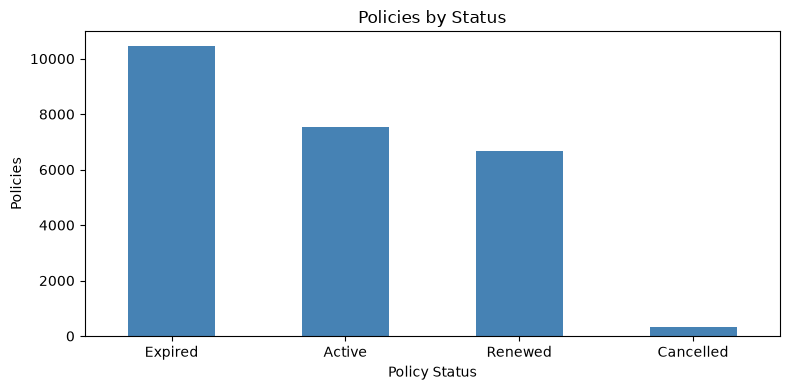

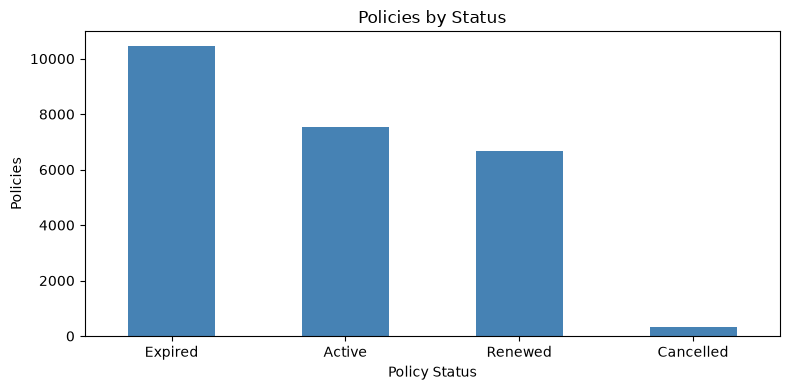

In [51]:
import importlib
import src.visualization as visualization

importlib.reload(visualization)

fig = visualization.plot_policy_status(data)
display(fig)

In [52]:
import importlib
import src.insights as insights

importlib.reload(insights)

for generator in [
    insights.generate_portfolio_insights,
    insights.generate_claim_insights,
    insights.generate_premium_insights,
    insights.generate_customer_insights,
    insights.generate_vehicle_insights,
    insights.generate_risk_patterns,
]:
    for item in generator(data):
        print("\nPATTERN:", item["pattern"])
        print("EVIDENCE:", item["evidence"])
        print("BUSINESS MEANING:", item["business_meaning"])
        print("RECOMMENDATION:", item["recommendation"])


PATTERN: Expired is the most common policy status.
EVIDENCE: 10,464 of 25,000 policies (41.9%) are Expired.
BUSINESS MEANING: The largest status group describes a substantial part of the policy portfolio.
RECOMMENDATION: Review this segment alongside renewal and cancellation trends when planning portfolio actions.

PATTERN: Accident is the most common claim type.
EVIDENCE: It accounts for 4,838 claims.
BUSINESS MEANING: This type contributes the largest claim volume in the dataset.
RECOMMENDATION: Review this claim type by severity, vehicle age, and settlement time to identify operational patterns.

PATTERN: Fire has the highest average claim amount.
EVIDENCE: Its average claim amount is 299,284.75 across 759 claims.
BUSINESS MEANING: A high average claim amount may have a different cost impact from a high-volume claim type.
RECOMMENDATION: Review a sample of these claims and compare their damage severity and settlement outcomes.

PATTERN: Comprehensive policies generate the highest t